In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [2]:
# 1. Silence C++ backend warnings (Must be before importing/using TF operations)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

try:
    import tensorflow as tf
except:
    !uv pip install tensorflow
    import tensorflow as tf

from tensorflow.keras.utils import FeatureSpace
from tensorflow.keras.utils import plot_model
# os.environ["KERAS_BACKEND"] = "tensorflow"

import logging

# 2. Silence Python level TensorFlow/ABSL warnings
tf.get_logger().setLevel(logging.ERROR)
logging.getLogger('tensorflow').setLevel(logging.ERROR)
logging.getLogger('absl').setLevel(logging.ERROR)

I0000 00:00:1795346157.380750    5833 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795346159.841444    5833 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
# !pip install -q ipywidgets
# !pip install -q pygraphviz
# !apt-get install -qq -y graphviz graphviz-dev && pip install -qq pydot

In [4]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [5]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import shutil
import itertools
from tqdm.auto import tqdm
from time import time, sleep

from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, PredictionErrorDisplay, RocCurveDisplay
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer, LabelEncoder, TargetEncoder as skTE

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, MissingIndicator, SimpleImputer

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

pd.set_option("display.max_columns", 100)
# sns.set_style("whitegrid")

def seed_everything(seed: int):
    print(f"✓ Seed everything at {seed}")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

✓ Seed everything at 42


In [6]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [7]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")
    
## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [8]:
n_unique = train.nunique().sort_values()
n_unique

is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

In [9]:
def get_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        class_weights = opt
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights
    else:
        classes_ = np.unique(y_true)
        weights_ = compute_class_weight('balanced', classes=classes_, y=y_true)
        class_weights = dict(zip(classes_, weights_))
        sample_weights = np.array([class_weights[label] for label in y])
        return class_weights

## -- Reduce data memory --
def reduce_memory(df):
    old_size = sys.getsizeof(df) / (1024*1024)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = sys.getsizeof(df) / (1024**2)
    print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

    return df

print('- Helper Functions Ready -')

- Helper Functions Ready -


In [10]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_trn, y_trn = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_trn.copy()
            temp_df_train['target'] = y_trn

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_trn.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [11]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df, on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [12]:
%%time

ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

print('-'*40)
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

# category_map = {}
# important_combos = [
#     ('merchant_category', 'card_type', 'txn_count_last_24h'),
#     ('merchant_category', 'customer_age'),
# ]
# def feature_engineering(df, fit=False):
#     # Digit extraction
#     for col in ['amount_usd', 'hours_since_last_txn',
#                 'velocity_score', 'distance_from_home_km']:
#         decimal_name = f"_{col}_decimal"
#         df[decimal_name] = (df[col] % 1).round(2).astype('float32')

#     # Categorize numericals
#     for col in num_cols + ['_amount_usd_decimal', '_hours_since_last_txn_decimal',
#                            '_velocity_score_decimal', '_distance_from_home_km_decimal']:
#         cat_name = f"{col}_cat_" if col in num_cols else f"{col[1:]}_cat_"
#         values = np.floor(df[col]) if col in num_cols else df[col]
#         if fit:
#             codes, uniques = values.factorize()
#             category_map[col] = uniques
#         else:
#             uniques = category_map[col]
#             code_map = {cat: i for i, cat in enumerate(uniques)}
#             codes = values.map(code_map).fillna(-1).astype('int32')
#         df[cat_name] = codes
#         df[cat_name] = df[cat_name].astype('category')

#     # Discretize numericals
#     bin_config = {'merchant_risk_score': [7], 'hours_since_last_txn': [500, 1000]}
#     for col, bins_list in bin_config.items():
#         for n_bins in bins_list:
#             for strategy in ['quantile']:
#                 bin_name = f"{col}_{n_bins}_{strategy}_bin_"
#                 if fit:
#                     kb = KBinsDiscretizer(
#                         n_bins=n_bins,
#                         encode='ordinal',
#                         strategy=strategy,
#                         subsample=None
#                     )
#                     binned = kb.fit_transform(df[[col]]).ravel().astype('int32')
#                     category_map[bin_name] = kb
#                 else:
#                     kb = category_map[bin_name]
#                     binned = kb.transform(df[[col]]).ravel().astype('int32')
#                 df[bin_name] = binned
#                 df[bin_name] = df[bin_name] #.astype('category')

#     # Create interaction categories
#     combo_names = []
#     for cols in important_combos:
#         combo_name = '_'.join(cols) + '_'
#         combo_names.append(combo_name)
#         combo_series = df[cols[0]].astype(str)
#         for col in cols[1:]:
#             combo_series = combo_series + '_' + df[col].astype(str)
#         if fit:
#             codes, uniques = pd.factorize(combo_series, sort=False)
#             category_map[combo_name] = uniques
#         else:
#             uniques = category_map[combo_name]
#             code_map = {cat: i for i, cat in enumerate(uniques)}
#             codes = combo_series.map(code_map).fillna(-1).astype('int32')
#         df[combo_name] = codes
#         df[combo_name] = df[combo_name] #.astype('category')

#     new_cat_cols = [col for col in df.columns if col.endswith('_')]
#     new_num_cols = [col for col in df.columns if col.startswith('_')]
#     return df, new_cat_cols, new_num_cols, combo_names

# X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
# X_test, _, _, _ = feature_engineering(X_test, fit=False)
# cat_cols += new_cat_cols; num_cols += new_num_cols
# print("len(new_cat_cols):", len(new_cat_cols))
# print("len(new_num_cols):", len(new_num_cols), "\n")

# print("prep len(cat_cols):", len(cat_cols))
# print("prep len(num_cols):", len(num_cols), "\n")
# print("X      prep shape:", X.shape)
# print("X_test prep shape:", X_test.shape, "\n")
# print('-'*40)

----------------------------------------
X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

CPU times: user 74 ms, sys: 38.9 ms, total: 113 ms
Wall time: 111 ms


In [13]:
X.dtypes

amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                object
card_type                        object
auth_method                      object
channel                          object
device_type                      object
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool
dtype: object

In [14]:
float_cols = X.select_dtypes(include=['float']).columns.tolist()
int_cols = X.select_dtypes(include=['int']).columns.tolist()
obj_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

X[obj_cols] = X[obj_cols].astype(str) #.astype('category')
X_test[obj_cols] = X_test[obj_cols].astype(str) #.astype('category')

# X = reduce_memory(X)
# X_test = reduce_memory(X_test)
# print(f"Data memory reduced!")

FEATURES = [c for c in X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

X.head()

Total Features: 24


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False


In [15]:
# ## -- Cyclic encoding --
# CYCLICS = []
# cy_cols = [c for c in train.columns if c.endswith("_hours")]

# for col in tqdm(cy_cols):
#     for p in [12, 24]:
#         n_s = f"{col}_sin_{p}"

#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         orig[n_s]  = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         test[n_s]  = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         CYCLICS.append(n_s)

#         # n_c = f"{col}_cos_{p}"
#         # train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')
#         # test[n_c] = np.cos(2 * np.pi * test[col] / p).astype('float32')
#         # orig[n_c] = np.cos(2 * np.pi * orig[col] / p).astype('float32')
#         # CYCLICS.append(n_c)

# # NUMS.extend(CYCLICS)

# print(f"Cylcic Features created: {len(CYCLICS)}")
# print(train[CYCLICS].describe().T)

# train[CYCLICS].head()

# ML TRAINING

In [24]:
def build_keras_mlp(
    feature_space: tf.keras.utils.FeatureSpace = None,
    layer_units: list = [128, 64, 32],
    learning_rate: float = 0.01,
    drop_rate: float = 0.1,
    activation: str = "relu",
    bias = True,
    l2_reg = tf.keras.regularizers.L2(0.0)
):
    # 1. Retrieve structural components from the globally adapted FeatureSpace
    dict_inputs = feature_space.get_inputs()
    encoded_features = feature_space.get_encoded_features()

    print(f"Input shape: {len(dict_inputs)}", end=" | ")
    print(f"FeatureSpace shape: {encoded_features.shape[1]} +++ MLP model +++")
    print('-'*60)

    # 2. Build the Core Deep Neural Network using the Functional API safely
    # This ensures layers are completely reusable across train/inference topologies
    x = encoded_features

    # Clean, dynamic looping over layer configuration list
    for units in layer_units:
        x = tf.keras.layers.Dense(
            units,
            activation=activation,
            use_bias=bias,
            kernel_regularizer=l2_reg)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Dropout(drop_rate)(x)

    # Final Binary Classification Output Node
    final_output = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    train_model = tf.keras.Model(inputs=encoded_features, outputs=final_output)
    infer_model = tf.keras.Model(inputs=dict_inputs, outputs=final_output)

    train_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, weight_decay=0.0),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc")]
    )

    return train_model, infer_model

print("⚙️ Keras mlp model ready ⚙️")

⚙️ Keras mlp model ready ⚙️


In [25]:
def build_keras_seq(
    feature_space: tf.keras.utils.FeatureSpace = None,
    layer_units: list = [128, 64, 32],
    learning_rate: float = 0.01,
    drop_rate: float = 0.1,
    activation: str = "relu",
    bias = True,
    l2_reg = tf.keras.regularizers.L2(0.0),
):

    # 1. Setup Inputs
    dict_inputs = feature_space.get_inputs()
    encoded_features = feature_space.get_encoded_features()

    print(f"Input shape: {len(dict_inputs)}", end=" | ")
    print(f"FeatureSpace shape: {encoded_features.shape[1]} +++ Sequential model +++")
    print('-'*60)

    # 2. Create the Sequential model
    outputs = tf.keras.Sequential([
        # keras.Input(shape=shape),
        # Optional: Add BN here if your data isn't pre-scaled
        # keras.layers.BatchNormalization(),

        ## -- 1st Layer --
        tf.keras.layers.Dense(layer_units[0], activation, use_bias=bias,
                              kernel_regularizer=l2_reg),
        tf.keras.layers.BatchNormalization(),
        # tf.keras.layers.Activation('relu'),
        tf.keras.layers.Dropout(drop_rate),

        ## -- 2nd Layer --
        tf.keras.layers.Dense(layer_units[1], activation, use_bias=bias,
                              kernel_regularizer=l2_reg),
        tf.keras.layers.BatchNormalization(),
        # tf.keras.layers.Activation('relu'),
        tf.keras.layers.Dropout(drop_rate),

        ## -- 3rd Layer --
        tf.keras.layers.Dense(layer_units[2], activation, use_bias=bias,
                              kernel_regularizer=l2_reg),
        tf.keras.layers.BatchNormalization(),
        # keras.layers.Activation('relu'),
        tf.keras.layers.Dropout(drop_rate),

        ## -- Output --
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])(encoded_features)

    # Connect everything
    train_model = tf.keras.Model(inputs=encoded_features, outputs=outputs)
    train_model.compile(
        # optimizer=keras.optimizers.Adam(learning_rate, weight_decay=None), # 0.02
        # optimizer=tf.keras.optimizers.RMSprop(learning_rate),
        optimizer=tf.keras.optimizers.Adam(learning_rate, weight_decay=0.0),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc")]
        )

    infer_model = tf.keras.Model(inputs=dict_inputs, outputs=outputs)

    return train_model, infer_model

print("⚙️ Keras sequential model ready ⚙️")

⚙️ Keras sequential model ready ⚙️


In [26]:
# dir(FeatureSpace)

In [27]:
def _feature_space_transform(X, y, batch_size=128, feat_crosses=None):
    """Initializes and adapts Keras FeatureSpace globally once."""
    feature_specs = {}
    
    float_cols = X.select_dtypes(include=['float']).columns.tolist()
    int_cols = X.select_dtypes(include=['int']).columns.tolist()
    obj_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()

    for col in X.columns:
        if col in obj_cols:
            feature_specs[col] = FeatureSpace.string_categorical(num_oov_indices=1)
        elif col in float_cols:
            feature_specs[col] = FeatureSpace.float_normalized()
        elif col in int_cols:
            feature_specs[col] = FeatureSpace.integer_categorical(12, num_oov_indices=1)

    _fs = FeatureSpace(
        features=feature_specs,
        crosses=feat_crosses,
        output_mode="concat",
        name="fs_processed",
    )
    ds = tf.data.Dataset.from_tensor_slices((dict(X), y)).batch(batch_size)

    no_labels = ds.map(lambda x, _: x)
    print(f"📥 FeatureSpace.adapt() to {len(feature_specs)} features... ", end='')
    
    _fs.adapt(no_labels)
    print(f"✅ Complete!")

    return _fs

print("⚙️ Feature_Space function ready ⚙️")

⚙️ Feature_Space function ready ⚙️


In [28]:
CHECKPOINT = "checkpoints/"
shutil.rmtree(CHECKPOINT, ignore_errors=True)
os.makedirs(CHECKPOINT, exist_ok=True)

class CFG:
    TE    = True if 'combo_names' in globals() else False
    BIAS  = False # d=True
    MODEL = 'MLP' # MLP or SEQ
    FOLDS = 5
    SEED  = 42
    ACT   = 'relu' # 'relu', 'selu', 'gelu'
    LR    = 0.01
    EPOCH = 10
    STOP  = 4
    DROP  = 0.1
    UNITS = [256, 128, 64]
    BATCH = 1024 if torch.cuda.is_available() else 128

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        patience=CFG.STOP,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{CHECKPOINT}best_model.model.keras",
        monitor="val_auc",
        save_best_only=True,
    ),
]

dir(CFG)[:10]

['ACT',
 'BATCH',
 'BIAS',
 'DROP',
 'EPOCH',
 'FOLDS',
 'LR',
 'MODEL',
 'SEED',
 'STOP']

In [29]:
FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

tf.keras.backend.clear_session()

# Explicit multi-device strategy execution activation
strategy = tf.distribute.MirroredStrategy()
GLOBAL_BATCH_SIZE = CFG.BATCH * strategy.num_replicas_in_sync
print(f"⚙️ Number of devices: {strategy.num_replicas_in_sync}")

model_name = f"KerasFS_{CFG.ACT[:2]}({X.shape[1]}_{CFG.UNITS[0]}_{str(CFG.DROP).split('.')[1]})"
print(f"🚀 Training {model_name} with {FOLDS } Folds | device: {get_system_info()}")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_times = []
fold_scores = []
fold_histories = []
best_iterations = []

_cats_ = [c for c in cat_cols if c.endswith(("_cat_", "_bin_"))] #

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # Target encoding
    if CFG.TE:
        te_cols = combo_names + _cats_
        smooth  = 'auto'
        print(f"⚡️ TargetEncoding ({len(te_cols)}) • smooth={smooth}")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols
        X_trn = X_trn.drop(columns=combos_to_drop )
        X_val = X_val.drop(columns=combos_to_drop )
        X_tst = X_tst.drop(columns=combos_to_drop )
    # --------------------------------------------------------------------
    # ---- Imputation ----
    impute_nums = X_trn.columns[X_trn[X_trn.columns].isna().any()].tolist()
    # impute_nums = [c for c in X_trn.columns if c not in CATS]

    if len(impute_nums) > 0:
        print('⚡️ Imputing NaN values')
        imputer = SimpleImputer() #.set_output(transform="pandas")
        X_trn[impute_nums] = imputer.fit_transform(X_trn[impute_nums], y_trn)
        X_val[impute_nums] = imputer.transform(X_val[impute_nums])
        X_tst[impute_nums] = imputer.transform(X_tst[impute_nums])
    # --------------------------------------------------------------------
    # ---- FeatureSpace Adaptation ----  
    FS_module = _feature_space_transform(
        X=X_trn,
        y=y_trn,
        batch_size=GLOBAL_BATCH_SIZE,
        # feat_crosses=None, # list of tuple-pairs ->[(). (), ()]
    )

    # PERFORMANCE FIX: Formulate explicit dictionary naming structures mapping directly into placeholders
    X_trn_ds = tf.data.Dataset.from_tensor_slices((dict(X_trn), y_trn)).batch(GLOBAL_BATCH_SIZE)
    prep_trn_ds = (X_trn_ds.map(
        lambda x, y: (FS_module(x), y), 
        num_parallel_calls=tf.data.AUTOTUNE
    ).cache().shuffle(buffer_size=len(X_trn)).prefetch(tf.data.AUTOTUNE))

    X_val_ds = tf.data.Dataset.from_tensor_slices((dict(X_val), y_val)).batch(GLOBAL_BATCH_SIZE)
    prep_val_ds = (X_val_ds.map(
        lambda x, y: (FS_module(x), y), 
        num_parallel_calls=tf.data.AUTOTUNE
    ).cache().prefetch(tf.data.AUTOTUNE))

    # Distribute execution matrices smoothly over available cores
    dist_train_ds = strategy.experimental_distribute_dataset(prep_trn_ds)
    dist_valid_ds = strategy.experimental_distribute_dataset(prep_val_ds)

    # Wrap model building and compiling inside the active strategy scope block
    # with strategy.scope():
    model = build_keras_mlp if CFG.MODEL == 'MLP' else build_keras_seq
    train_model, infer_model = model(
        feature_space=FS_module,
        drop_rate=CFG.DROP,
        layer_units=CFG.UNITS,
        learning_rate=CFG.LR,
        activation=CFG.ACT,
        bias=CFG.BIAS,
    )

    print(f"    🟢 Training Model Graph...")
    history = train_model.fit(
        dist_train_ds,
        validation_data=dist_valid_ds,
        epochs=CFG.EPOCH,
        callbacks=callbacks,
        verbose=1,
    )
    fold_histories.append(history.history)

    # CACHING INFERENCE CHANNELS: Cache transformed evaluation datasets to save CPU cycles
    X_val_infer_ds = tf.data.Dataset.from_tensor_slices(dict(X_val))\
                                    .batch(GLOBAL_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    X_tst_infer_ds = tf.data.Dataset.from_tensor_slices(dict(X_tst))\
                                    .batch(GLOBAL_BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    # HIGH EFFICIENCY PREDICTION: Route raw data dictionaries directly into the inference graph
    # print(f"    🔵 Evaluating Out-of-Fold Predictions...")
    val_preds = infer_model.predict(X_val_infer_ds).ravel()
    oof_preds[val_idx] = val_preds

    # print(f"    🟡 Calculating Test Inferences...")
    fold_test_preds = infer_model.predict(X_tst_infer_ds).ravel()
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    best_iter = len([*history.history.values()])
    best_iterations.append(best_iter)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print("-"*22)
    print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ iter= {best_iter}, time= {ff} mins ]\n")

test_preds /= FOLDS

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")

for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s} @ epoch={t}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
fold_results[f'epoch'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n") 

del FS_module, dist_train_ds, dist_valid_ds, X_val_infer_ds, X_tst_infer_ds

⚙️ Number of devices: 1
🚀 Training KerasFS_re(24_256_1) with 5 Folds | device: CPU: 4
### Fold 1/5
📥 FeatureSpace.adapt() to 24 features... ✅ Complete!
Input shape: 24 | FeatureSpace shape: 131 +++ MLP model +++
------------------------------------------------------------
    🟢 Training Model Graph...
Epoch 1/10
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 31s 6ms/step - auc: 0.9099 - loss: 0.0551 - val_auc: 0.9243 - val_loss: 0.0493
Epoch 2/10
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 24s 5ms/step - auc: 0.9200 - loss: 0.0511 - val_auc: 0.9201 - val_loss: 0.0493
Epoch 3/10
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 24s 5ms/step - auc: 0.9224 - loss: 0.0503 - val_auc: 0.9256 - val_loss: 0.0499
Epoch 4/10
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 23s 5ms/step - auc: 0.9237 - loss: 0.0500 - val_auc: 0.9220 - val_loss: 0.0495
Epoch 5/10
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 24s 5ms/step - auc: 0.9255 - loss: 0.0497 - val_auc: 0.9195 - val_loss: 0.1017
Epoch 6/10
4375/4375 ━━━━━━━━━━━━━━━━━━━━ 24s 5ms/step - auc: 0.9257 - loss: 0.0493 - val_au

In [ ]:
# ======================================== BIAS=True
# 5-FOLD CV: KerasFS_re(24_256_1) | (559968, 24)
# ==================================================
#  • Fold 1 AUC: 0.93449 @ epoch=4
#  • Fold 2 AUC: 0.94057 @ epoch=4
#  • Fold 3 AUC: 0.94185 @ epoch=4
#  • Fold 4 AUC: 0.9361 @ epoch=4
#  • Fold 5 AUC: 0.93194 @ epoch=4
# --------------------------------------------------
# OOF score: 0.93213
# AVG score: 0.93699 ± 0.00371
# --------------------------------------------------
# 29.67 mins

# ======================================= BIAS=False
# 5-FOLD CV: KerasFS_re(24_256_1) | (559968, 24)
# ==================================================
#  • Fold 1 AUC: 0.93678 @ epoch=4
#  • Fold 2 AUC: 0.93731 @ epoch=4
#  • Fold 3 AUC: 0.94226 @ epoch=4
#  • Fold 4 AUC: 0.93455 @ epoch=4
#  • Fold 5 AUC: 0.93095 @ epoch=4
# --------------------------------------------------
# OOF score: 0.93272
# AVG score: 0.93637 ± 0.0037
# --------------------------------------------------
# 26.78 mins

In [23]:
# dir(train_model)
# for v in history.history.values():
#     print(v)

In [30]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*25)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
KerasFS_re(24_256_1)_93699
-------------------------
29.7 mins



,auc,epoch,time(min)
fold 1,0.93449,4,6.86
fold 2,0.94057,4,6.63
fold 3,0.94185,4,7.02
fold 4,0.93610,4,4.58
fold 5,0.93194,4,4.57


In [31]:
submit[TARGET] = test_preds

# submit.to_csv(f"submit_{n}.csv", index=False)
# np.save(f"oof_{n}.npy", oof_preds)
# np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000237
1,699961,0.000449
2,699962,0.088398
3,699963,0.001781
4,699964,0.001903


In [32]:
# !rm -r /kaggle/working

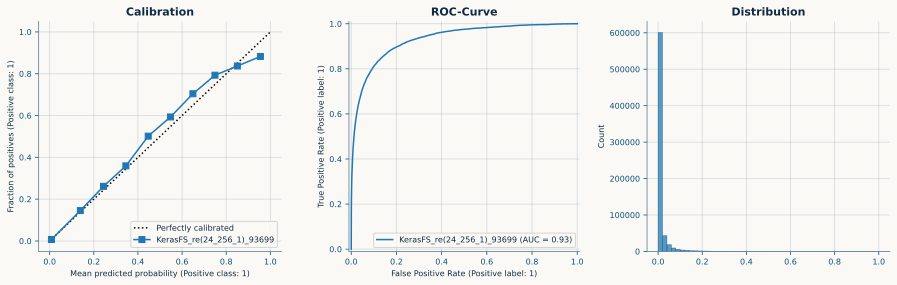

In [33]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [34]:
# histories = {}
# fold_scores = {}

# for k, v in all_predictions.items():
#     for x, y in v.items():
#         if x == "history":
#             histories[k] = y
#         elif x == "fold_score":
#             fold_scores[k] = y

# fold_scores

In [35]:
# for i, (data, score) in tqdm(enumerate(zip(histories.values(), fold_scores.values()))):
#     print("Hist", data[i]['auc'])
#     print(score[i])
#     break

In [36]:
# ## -- Plot results --
# histories = {}

# for i, (k, v) in enumerate(all_predictions.items()):
#     for j, (x, y) in enumerate(v.items()):
#         if x == "history":
#             histories[k] = y
#             # print(y)
#             loss_results = pd.DataFrame({'train_loss': y[i]['loss'], 'val_loss': y[i]['val_loss']})
#             auc_results  = pd.DataFrame({'train_auc': y[i]['auc'], 'val_auc': y[i]['val_auc']})

#             plt.figure(figsize=(16, 5))
#             marker = 'o'

#             ## -- Plot LOSS --
#             plt.subplot(121)
#             sns.lineplot(loss_results, x=loss_results.index, y=loss_results.train_loss, label='train_loss', marker=marker)
#             sns.lineplot(loss_results, x=loss_results.index, y=loss_results.val_loss, label='val_loss', marker=marker)
#             plt.title(f"- LOSS -", fontweight='semibold')
#             plt.xlabel('Epochs')
#             plt.ylabel('Loss')
        
#             ## -- Plot AUC --
#             plt.subplot(122)
#             sns.lineplot(auc_results, x=auc_results.index, y=auc_results.train_auc, label='train_auc', marker=marker)
#             sns.lineplot(auc_results, x=auc_results.index, y=auc_results.val_auc, label='val_auc', marker=marker)
#             plt.title(f"- AUC -", fontweight='semibold')
#             plt.xlabel('Epochs')
#             plt.ylabel('AUC')
#             min_value = min(min(auc_results.train_auc)-1e-3, min(auc_results.val_auc-1e-3))
#             max_value = max(max(auc_results.train_auc+1e-3), max(auc_results.val_auc+1e-3))
#             plt.ylim((min_value, max_value))

#             stat_ = f"fold_auc: {fold_scores[k][i]:.6f}"
#             plt.scatter(x=0, y=0, label=stat_, color='g')
        
#             plt.suptitle(f"{k}: FOLD {i+1}", fontsize=15, fontweight='semibold')
#             plt.legend(loc='lower right')
#             plt.tight_layout()
#             plt.show()
        
#             print()
        
#             # break

In [37]:
# ## -- Plotting results --

# for i, (k, v) in enumerate(histories.items()):
#     print(k)
#     for j, (fold, score) in enumerate(zip(v, fold_score)):
#         loss_results = pd.DataFrame({'train_loss': fold['loss'], 'val_loss': fold['val_loss']})
#         auc_results = pd.DataFrame({'train_auc': fold['auc'], 'val_auc': fold['val_auc']})
#         plt.figure(figsize=(16, 5))
#         marker = 'o'
    
#         ## -- PLOT LOSS --
#         plt.subplot(121)
#         sns.lineplot(loss_results, x=loss_results.index, y=loss_results.train_loss, label='train_loss', marker=marker)
#         sns.lineplot(loss_results, x=loss_results.index, y=loss_results.val_loss, label='val_loss', marker=marker)
#         plt.title(f"{k} LOSS", fontweight='semibold')
#         plt.xlabel('Epochs')
#         plt.ylabel('Loss')
    
#         ## -- PLOT AUC --
#         plt.subplot(122)
#         sns.lineplot(auc_results, x=auc_results.index, y=auc_results.train_auc, label='train_auc', marker=marker)
#         sns.lineplot(auc_results, x=auc_results.index, y=auc_results.val_auc, label='val_auc', marker=marker)
#         plt.title(f"{k} AUC", fontweight='semibold')
#         plt.xlabel('Epochs')
#         plt.ylabel('AUC')
#         min_value = min(min(auc_results.train_auc)-1e-3, min(auc_results.val_auc-1e-3))
#         max_value = max(max(auc_results.train_auc+1e-3), max(auc_results.val_auc+1e-3))
#         plt.ylim((min_value, max_value))
    
#         stat_ = f"fold_auc: {score[j]:.6f}"
#         plt.scatter(x=0, y=0, label=stat_, color='y')
    
#         plt.suptitle(f"FOLD {j+1}", fontsize=15, fontweight='semibold')
#         plt.legend(loc='best')
#         plt.tight_layout()
#         plt.show()
#         print()

In [38]:
# if len(model_results.columns) > 1:
#     # display(model_results.corr("spearman"))
#     fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
#     sns.heatmap(model_results.corr("spearman"), annot=True, fmt=".4g", cbar=False, ax=ax1)
#     ax1.set_title('Heatmap Correlation (Spearman)', fontsize=14, fontweight='bold')
    
#     sns.ecdfplot(data=model_results, linewidth=2, ax=ax2)
#     ax2.set_title('CDF Comparison of 5 Probability Distributions', fontsize=14, fontweight='bold')
#     ax2.set_xlabel('Probability Value', fontsize=12)
#     ax2.set_ylabel('Cumulative Proportion (CDF)', fontsize=12)
#     ax2.grid(True, linestyle='--', alpha=0.6)
    
#     plt.tight_layout()
#     plt.show()